# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [13]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = (1920 * 1080 * 3) / 1_000_000

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 60 * 60

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = (1920 * 1080 * 3 * frames_per_day * 400) / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = (640 * 360 * 3 * 10 * 24 * 60 * 60 * 400) / (1024 ** 4)
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 6.22 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_**Spatial evidence:** Downsampling from 1080p to 360p can remove fine details such as a person's facial features, clothing patterns, or a small object held in their hand.

**Temporal evidence:** Reducing the frame rate from 30 fps to 10 fps can miss brief actions, such as a person dropping an object or making a quick hand movement. These events may occur between the retained frames.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

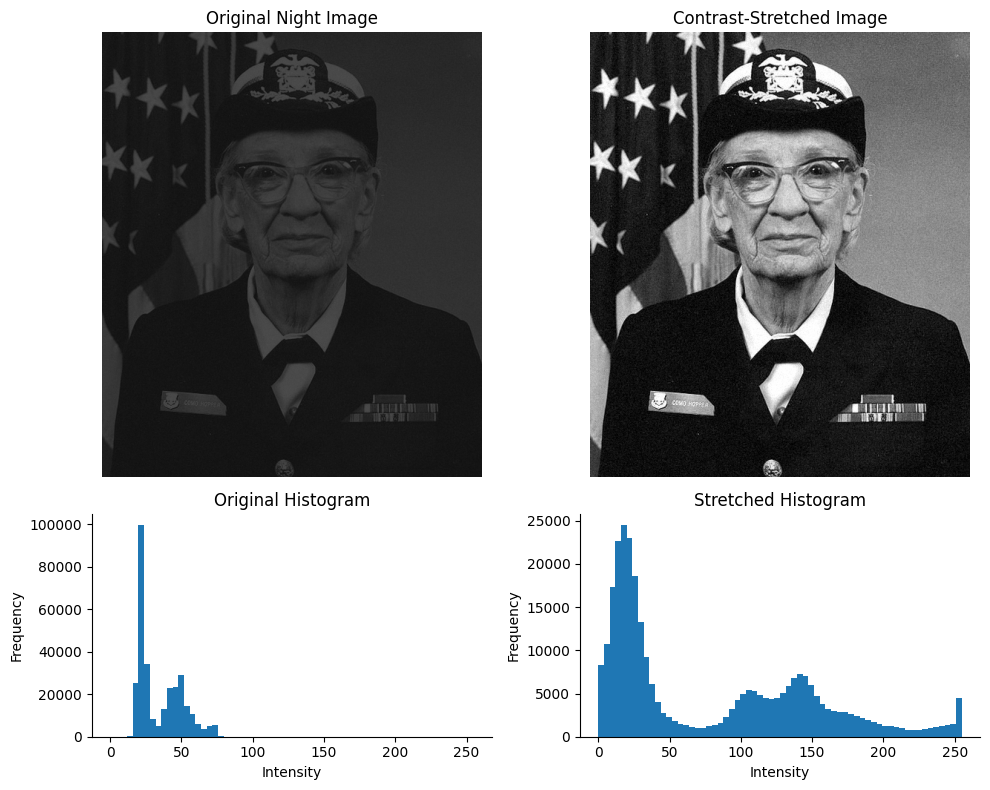

Contrast before: 0.609 -> after: 1.000


In [14]:

def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip(
    (night_still - p1) * 255 / (p99 - p1),
    0, 255
)

c_after = michelson(
    np.percentile(stretched, 99),
    np.percentile(stretched, 1)
)

fig, axes = plt.subplots(
    2, 2, figsize=(10, 8),
    gridspec_kw={"height_ratios": [2, 1]}
)

# TODO 1: original image and histogram
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Night Image")
axes[0, 0].axis("off")

axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255))
axes[1, 0].set_title("Original Histogram")
axes[1, 0].set_xlabel("Intensity")
axes[1, 0].set_ylabel("Frequency")

# TODO 4: stretched image and histogram
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-Stretched Image")
axes[0, 1].axis("off")

axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255))
axes[1, 1].set_title("Stretched Histogram")
axes[1, 1].set_xlabel("Intensity")
axes[1, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print(f"Contrast before: {c_before:.3f} -> after: {c_after:.3f}")


**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_The original night image has a narrow, low-intensity histogram concentrated toward the darker end, indicating low contrast. Contrast stretching expands the occupied intensity range to make differences between pixels more visible. However, it does not add new information because it only remaps existing pixel values; details lost during image acquisition cannot be recovered by stretching alone. A histogram shows the distribution of pixel intensities but not their spatial arrangement, so different images can have the same histogram while depicting entirely different scenes.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).


Standing (speed < 3 px/s):
68.7s - 68.7s
68.8s - 68.8s
68.9s - 70.5s
70.6s - 70.8s
70.9s - 71.1s
71.2s - 71.6s
71.7s - 72.0s
72.1s - 72.1s
72.2s - 72.7s
72.8s - 73.2s
73.3s - 73.7s
73.8s - 73.9s
74.0s - 74.0s
74.1s - 74.2s
74.3s - 74.7s
74.7s - 75.4s
75.4s - 75.5s
75.5s - 75.6s
75.6s - 75.7s
75.7s - 75.7s
75.8s - 75.9s
76.0s - 76.5s
76.6s - 76.9s
77.0s - 78.1s

Running (speed > 25 px/s):
78.6s - 86.0s


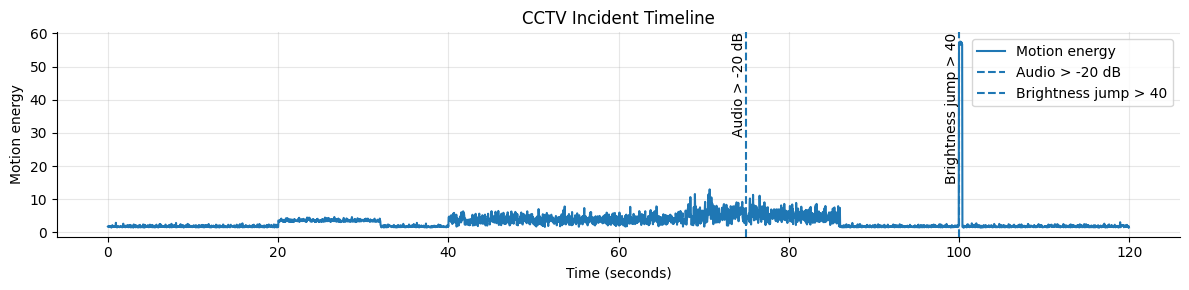

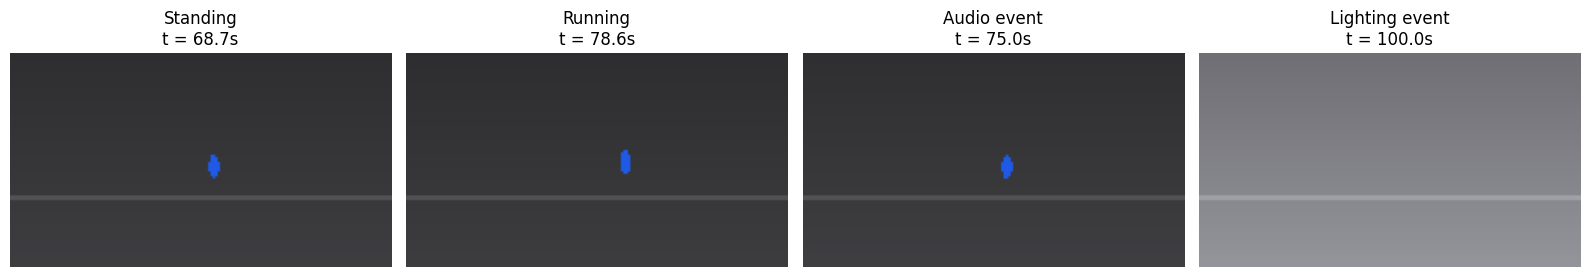

In [15]:

# TODO 1: person speed (px/s), using a 1-second window
dx = cctv["person_x"].diff(FPS)
dy = cctv["person_y"].diff(FPS)

speed = np.sqrt(dx**2 + dy**2)
valid_person = cctv["person_x"].notna() & cctv["person_y"].notna()
speed = speed.where(valid_person)

# TODO 2: standing / running time ranges
times = np.arange(len(cctv)) / FPS

def print_ranges(mask, label):
    mask = np.asarray(mask.fillna(False), dtype=bool)
    starts = np.where(mask & ~np.r_[False, mask[:-1]])[0]
    ends = np.where(mask & ~np.r_[mask[1:], False])[0]

    print(f"\n{label}:")
    if len(starts) == 0:
        print("No matching intervals found.")
    else:
        for start, end in zip(starts, ends):
            print(f"{times[start]:.1f}s - {times[end]:.1f}s")

print_ranges(speed < 3, "Standing (speed < 3 px/s)")
print_ranges(speed > 25, "Running (speed > 25 px/s)")

# TODO 3: event frame indices
audio_event_idx = np.where(
    (cctv["audio_level_db"] > -20).to_numpy()
)[0]

audio_event_idx = int(audio_event_idx[0]) if len(audio_event_idx) else None

brightness_jump = cctv["mean_brightness"].diff()
lighting_events = np.where((brightness_jump > 40).to_numpy())[0]
lighting_event_idx = int(lighting_events[0]) if len(lighting_events) else None

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))

ax.plot(times, cctv["motion_energy"], label="Motion energy")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Motion energy")
ax.set_title("CCTV Incident Timeline")
ax.grid(True, alpha=0.3)

events = [
    (audio_event_idx, "Audio > -20 dB"),
    (lighting_event_idx, "Brightness jump > 40"),
]

for idx, label in events:
    if idx is not None:
        ax.axvline(times[idx], linestyle="--", label=label)
        ax.annotate(
            label,
            (times[idx], ax.get_ylim()[1]),
            rotation=90,
            va="top",
            ha="right"
        )

ax.legend()
plt.tight_layout()
plt.show()

# TODO 5: one keyframe per event
keyframes = []

standing_idx = np.where((speed < 3).fillna(False).to_numpy())[0]
running_idx = np.where((speed > 25).fillna(False).to_numpy())[0]

if len(standing_idx):
    keyframes.append(("Standing", int(standing_idx[0])))

if len(running_idx):
    keyframes.append(("Running", int(running_idx[0])))

if audio_event_idx is not None:
    keyframes.append(("Audio event", audio_event_idx))

if lighting_event_idx is not None:
    keyframes.append(("Lighting event", lighting_event_idx))

if keyframes:
    fig, axes = plt.subplots(
        1, len(keyframes),
        figsize=(4 * len(keyframes), 3)
    )
    axes = np.atleast_1d(axes)

    for ax, (label, idx) in zip(axes, keyframes):
        ax.imshow(render_frame(cctv.iloc[idx]))
        ax.set_title(f"{label}\nt = {times[idx]:.1f}s")
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No keyframes found for the specified events.")


**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_Uniform keyframes sampled every 20 seconds could miss brief events such as a sudden lighting change, a short burst of running, or an audio spike occurring between sample times. Content-based keyframe selection is more effective because it selects representative frames based on meaningful changes or detected events rather than fixed time intervals. This approach follows the event-driven, content-based keyframe selection concept discussed in Slide 40.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

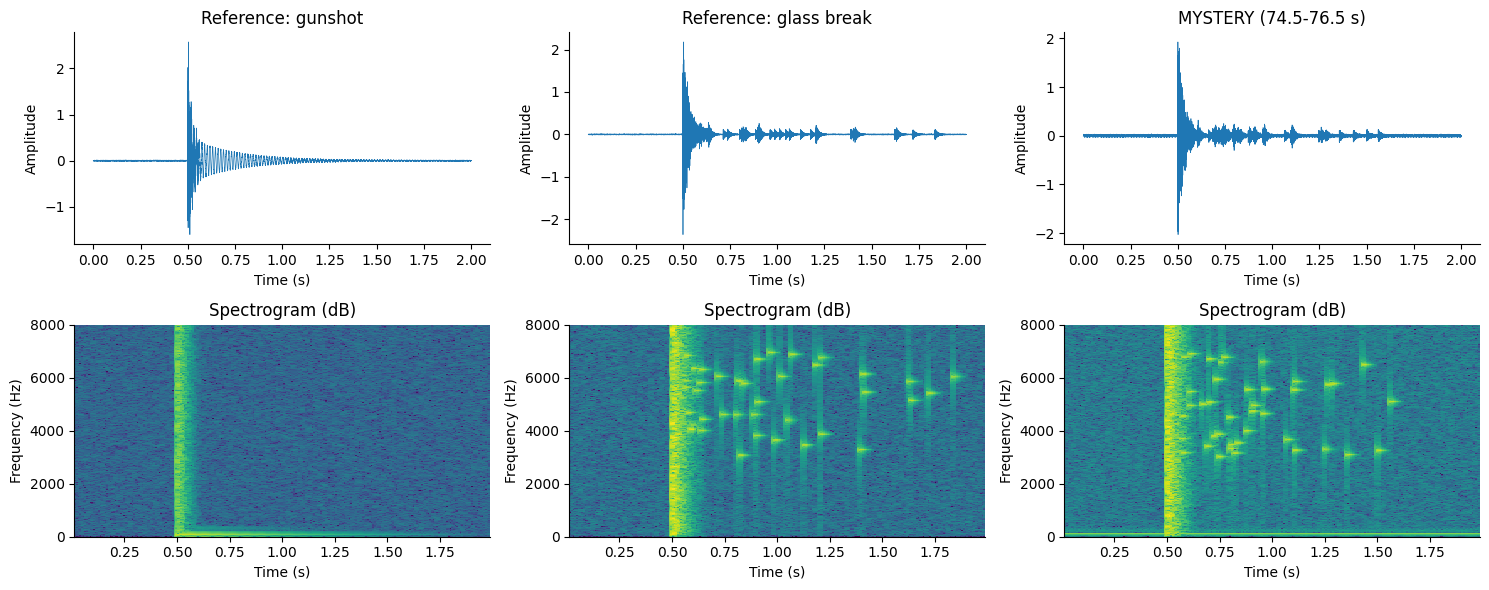

High-frequency energy fractions:
Reference: gunshot: 0.0031 (0.31%)
Reference: glass break: 0.9905 (99.05%)
MYSTERY (74.5-76.5 s): 0.8785 (87.85%)

Verdict: GLASS BREAK


In [17]:

# Prepare the three audio clips
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]

clips = {
    "Reference: gunshot": ref_gunshot[1],
    "Reference: glass break": ref_glass[1],
    "MYSTERY (74.5-76.5 s)": mystery
}

# TODO 1 & 2: Plot waveforms and spectrograms
fig, axes = plt.subplots(2, 3, figsize=(15, 6))

for col, (name, x) in enumerate(clips.items()):
    t = np.arange(len(x)) / FS

    axes[0, col].plot(t, x, linewidth=0.5)
    axes[0, col].set_title(name)
    axes[0, col].set_xlabel("Time (s)")
    axes[0, col].set_ylabel("Amplitude")

    f, ts, Sxx = signal.spectrogram(
        x, fs=FS, nperseg=512, noverlap=384
    )

    Sxx_db = 10 * np.log10(Sxx + 1e-12)

    axes[1, col].pcolormesh(
        ts, f, Sxx_db, shading="auto"
    )
    axes[1, col].set_ylim(0, 8000)
    axes[1, col].set_title("Spectrogram (dB)")
    axes[1, col].set_xlabel("Time (s)")
    axes[1, col].set_ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

# TODO 3: Fraction of spectral energy above 3 kHz
hf_fraction = {}

for name, x in clips.items():
    segment = x[int(0.7 * FS):int(1.7 * FS)]

    freqs = np.fft.rfftfreq(len(segment), d=1 / FS)
    power = np.abs(np.fft.rfft(segment)) ** 2

    total_energy = np.sum(power)
    high_energy = np.sum(power[freqs > 3000])

    hf_fraction[name] = (
        high_energy / total_energy if total_energy > 0 else 0
    )

print("High-frequency energy fractions:")
for name, value in hf_fraction.items():
    print(f"{name}: {value:.4f} ({value * 100:.2f}%)")

# TODO 4: Verdict
gunshot_score = hf_fraction["Reference: gunshot"]
glass_score = hf_fraction["Reference: glass break"]
mystery_score = hf_fraction["MYSTERY (74.5-76.5 s)"]

verdict = (
    "GLASS BREAK"
    if abs(mystery_score - glass_score)
       < abs(mystery_score - gunshot_score)
    else "GUNSHOT"
)

print(f"\nVerdict: {verdict}")


**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

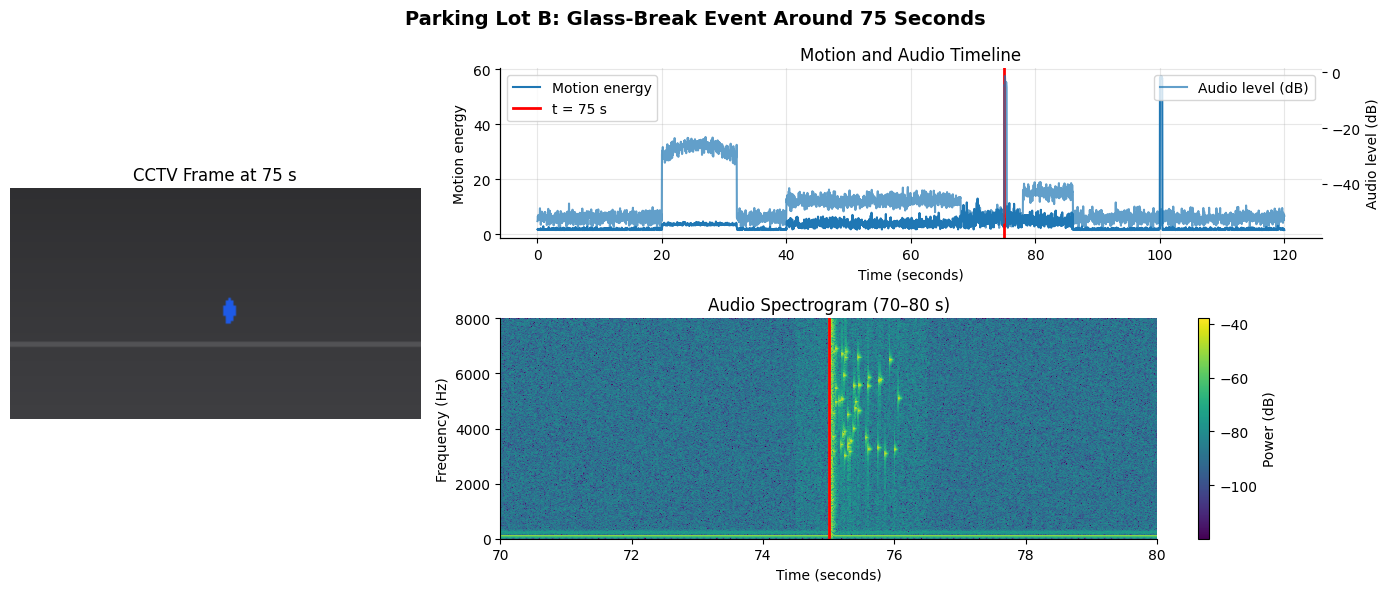

In [18]:

t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(
    2, 2,
    width_ratios=[1, 2],
    height_ratios=[1, 1.3]
)

# TODO 1: Video frame at t = 75 seconds
ax_frame = fig.add_subplot(gs[:, 0])
frame_idx = int(t_sel * FPS)
frame_idx = min(frame_idx, len(cctv) - 1)

ax_frame.imshow(render_frame(cctv.iloc[frame_idx]))
ax_frame.set_title("CCTV Frame at 75 s")
ax_frame.axis("off")

# TODO 2: Full 120-second motion + audio timeline
ax_timeline = fig.add_subplot(gs[0, 1])
video_times = np.arange(len(cctv)) / FPS

ax_timeline.plot(
    video_times,
    cctv["motion_energy"],
    label="Motion energy"
)
ax_timeline.set_xlabel("Time (seconds)")
ax_timeline.set_ylabel("Motion energy")
ax_timeline.set_title("Motion and Audio Timeline")
ax_timeline.grid(True, alpha=0.3)

# Overlay audio levels on a second y-axis
ax_audio = ax_timeline.twinx()
ax_audio.plot(
    video_times,
    cctv["audio_level_db"],
    label="Audio level (dB)",
    alpha=0.7
)
ax_audio.set_ylabel("Audio level (dB)")

# Red marker at 75 seconds
ax_timeline.axvline(
    t_sel, color="red", linewidth=2, label="t = 75 s"
)
ax_timeline.legend(loc="upper left")
ax_audio.legend(loc="upper right")

# TODO 3: Spectrogram of audio from 70 to 80 seconds
ax_spec = fig.add_subplot(gs[1, 1])

audio_times = t_audio[(t_audio >= 70) & (t_audio < 80)]
audio_segment = x_audio[(t_audio >= 70) & (t_audio < 80)]

f, ts, Sxx = signal.spectrogram(
    audio_segment,
    fs=FS,
    nperseg=512,
    noverlap=384
)

Sxx_db = 10 * np.log10(Sxx + 1e-12)

mesh = ax_spec.pcolormesh(
    70 + ts,
    f,
    Sxx_db,
    shading="auto",
    cmap="viridis"
)

ax_spec.set_ylim(0, 8000)
ax_spec.set_xlim(70, 80)
ax_spec.set_xlabel("Time (seconds)")
ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_title("Audio Spectrogram (70–80 s)")

# Same red marker at 75 seconds
ax_spec.axvline(t_sel, color="red", linewidth=2)
fig.colorbar(mesh, ax=ax_spec, label="Power (dB)")

# TODO 4: Conclusion-style title
fig.suptitle(
    "Parking Lot B: Glass-Break Event Around 75 Seconds",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_If the audio track were offset by +2 seconds, the sound event would appear two seconds later than its actual occurrence in the video, potentially leading to an incorrect interpretation of the incident sequence. The synchronized timeline and spectrogram would reveal the mismatch because their event markers would no longer align with the corresponding visual activity. This could cause the security team to associate the sound with the wrong action. Accurate synchronization is essential for reliable multimodal analysis and evidence-based conclusions.


## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_
Multimedia analysis requires balancing storage efficiency with the preservation of useful evidence. Downsampling and reducing frame rates can significantly reduce data volume, but they may remove fine spatial details and brief temporal events. Contrast stretching improves the visibility of existing image details without recovering information that was never captured. Audio classification benefits from combining waveform inspection, spectrogram analysis, and frequency-based features rather than relying on loudness alone. Finally, synchronizing video, motion, and audio timelines is essential for interpreting the sequence of events correctly. Together, these techniques demonstrate how spatial, temporal, and cross-modal evidence contribute to a more reliable multimedia briefing.